In [3]:
# Necessary libraries imported.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('marketing_campaign_aim.csv')
# Display first 5 rows
print(df.head())

# Dataset shape and info
print(f"Dataset Shape: {df.shape}")
print(df.info())

# Summary statistics
print(df.describe())

# Check for missing values
print(df.isnull().sum())

# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

   Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  AcceptedCmp3  \
0       58       635         88  ...                  7             0   
1       38        11          1  ...                  5             0   
2       26       426         49  ...                  4             0   
3       26        11          4  ...                  6             0   
4       94       173         43  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0      

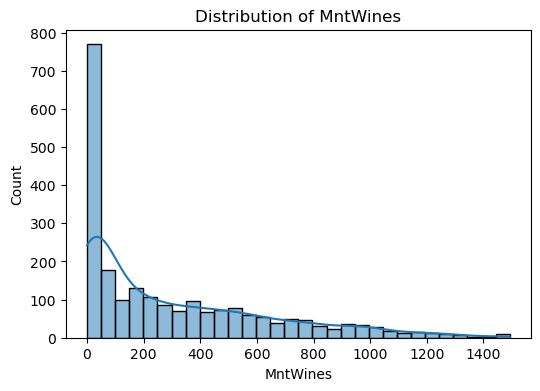

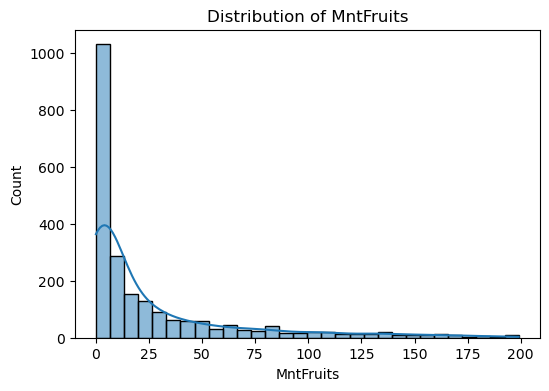

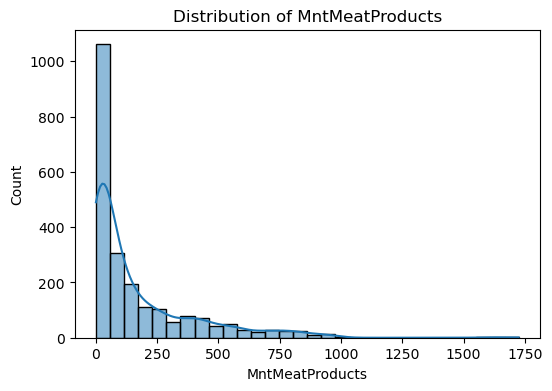

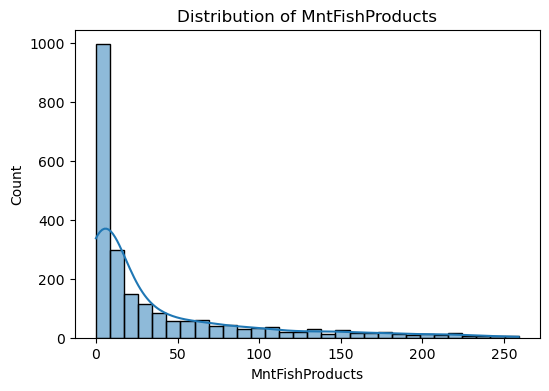

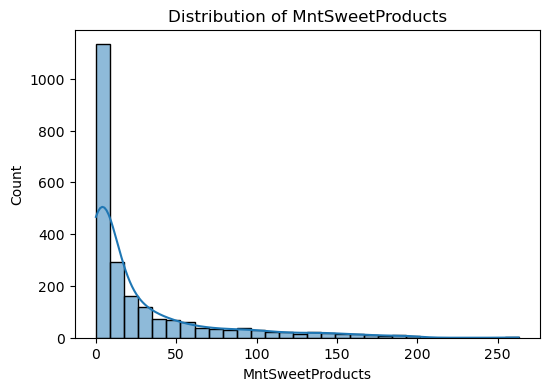

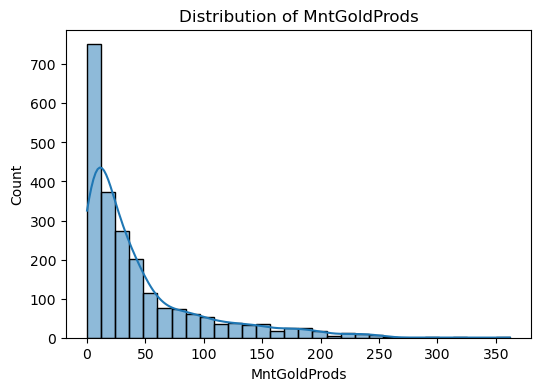

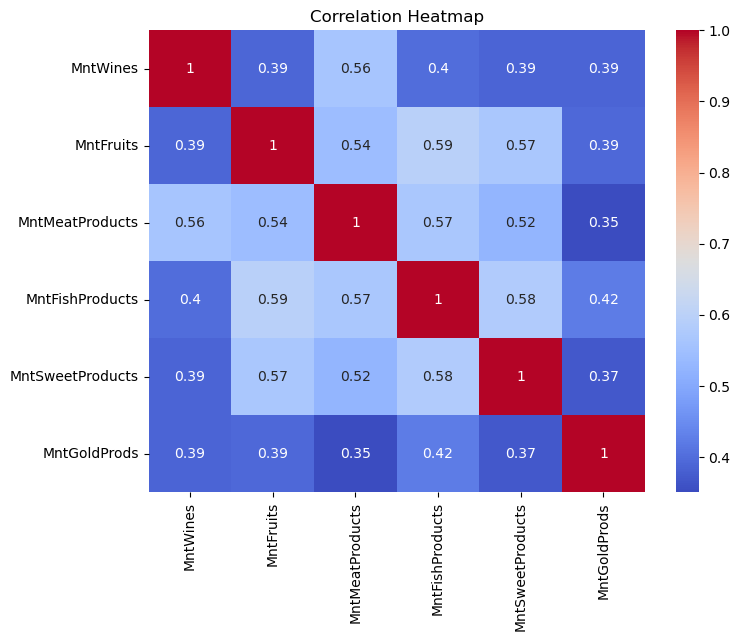

In [5]:
# Correlation heatmap graphical tool displays the strength and direction of relationships between multiple variables in a dataset using color
# +1 (Strong Positive Correlation), 0 (No Correlation), and -1 (Strong Negative Correlation)
# Color Intensity: The brighter or deeper the color, the stronger the relationship. Pale or neutral colors mean weak or zero correlation.
# One color (like blue or red) represents positive correlations. Income and Kidhome had high inverse or negative correlation based on above heatmap.

# Visualize distribution of numeric features
numeric_features = ['MntWines', 'MntFruits','MntMeatProducts','MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
    
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

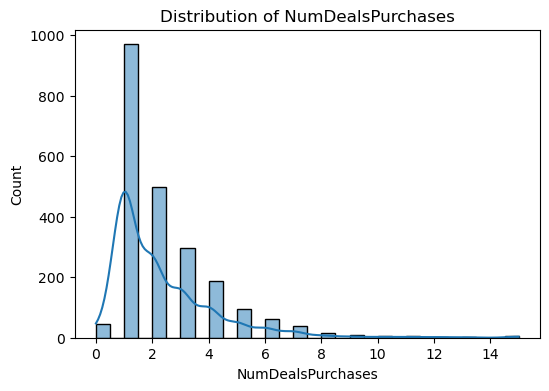

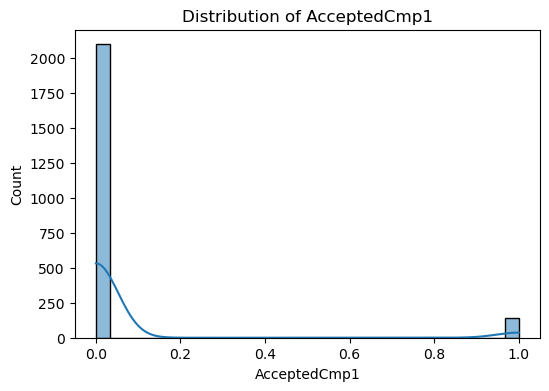

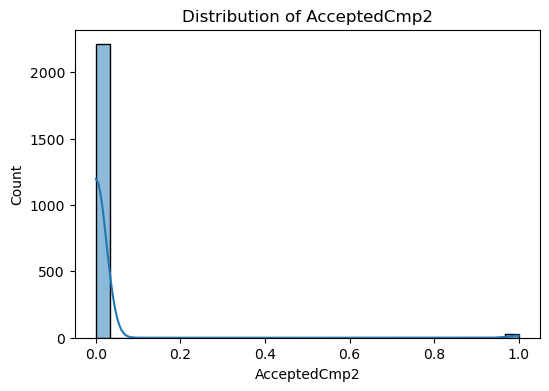

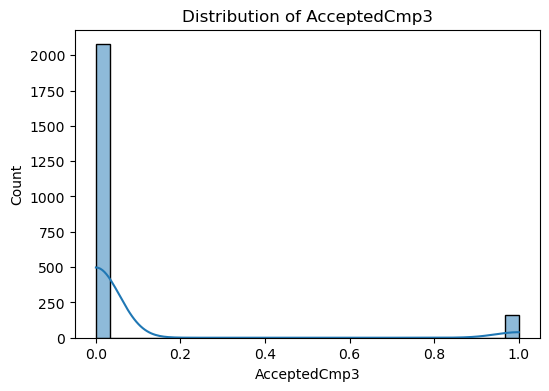

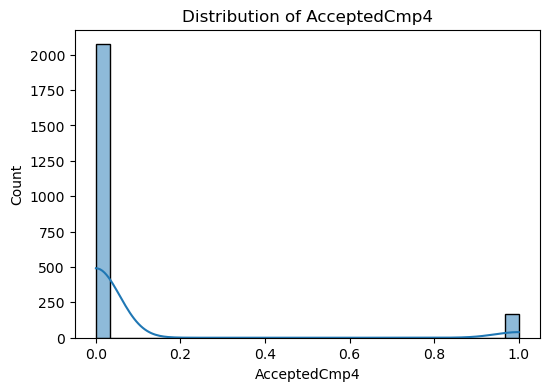

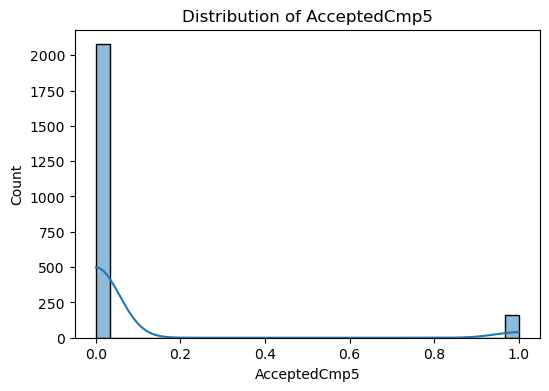

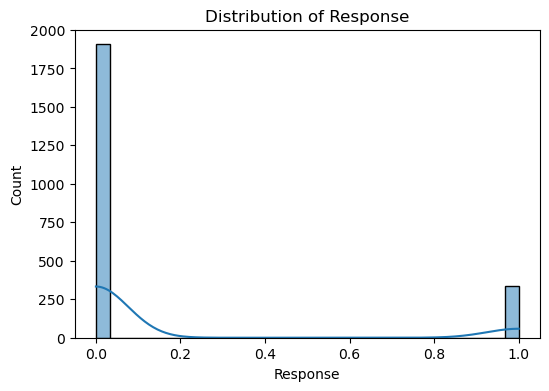

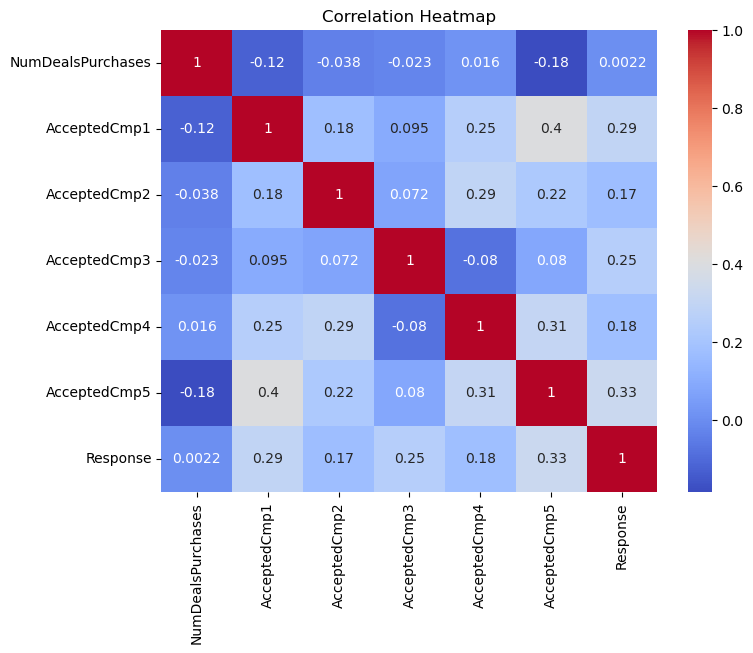

In [12]:
# Product correlation heatmap showed high correlation for MntFruits and MntFishProducts showing healthy food preference at 0.59.
# Followed by MntFruits and MntSweetProducts at 0.57 and MntWines and MntMeatProducts at 0.56. There is high chance that customers who buys meats also buy wines.

# Visualize distribution of numeric features
numeric_features = ['NumDealsPurchases', 'AcceptedCmp1','AcceptedCmp2','AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
    
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

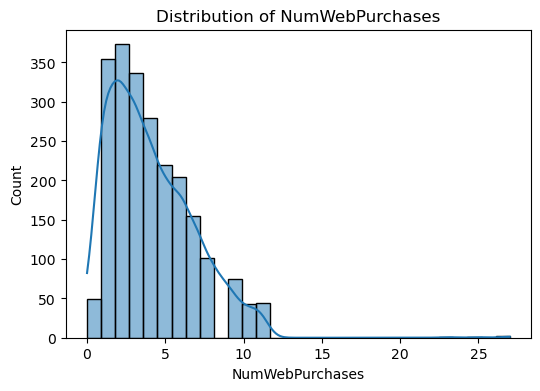

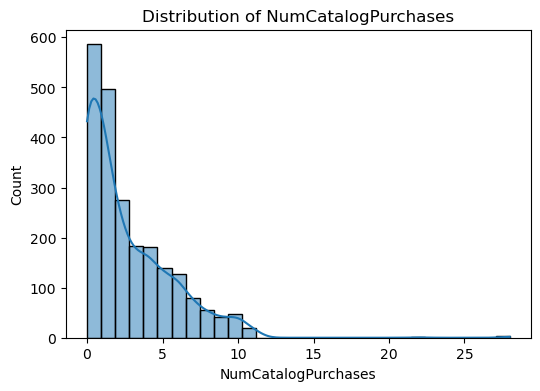

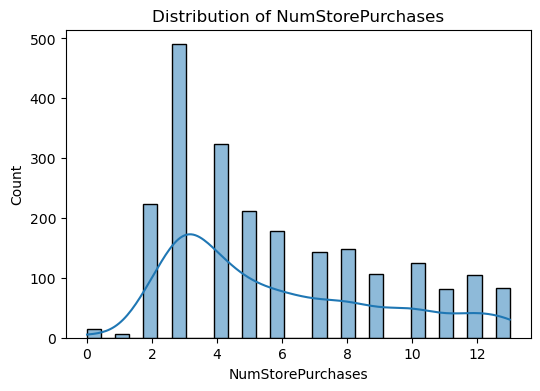

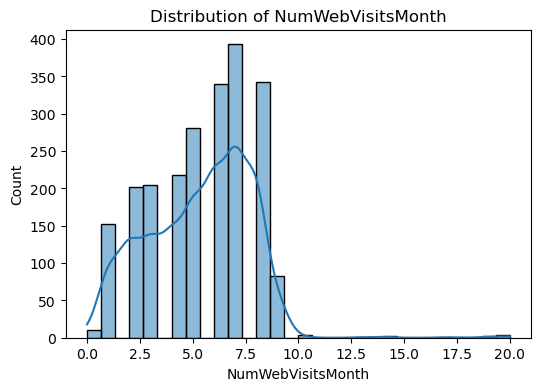

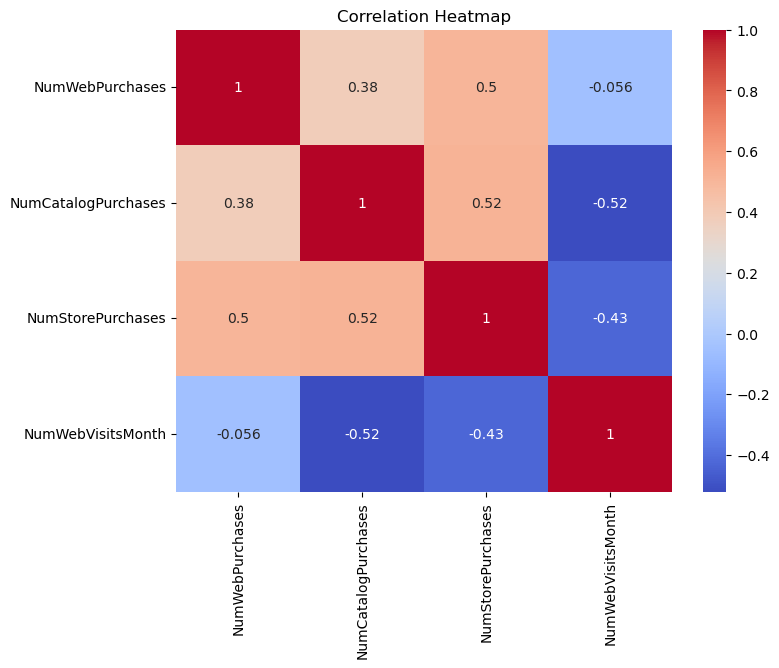

In [6]:
# On Promotion AcceptedCmp1 (customer accepted the offer in the 1st campaign) and AcceptedCmp5 (customer accepted offer in last campaign) are positively correlated

# Visualize distribution of numeric features
numeric_features = ['NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases','NumWebVisitsMonth']
    
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [7]:
# NumCatalogPurchases (number of purchases made using a catalogue) and NumStorePurchases number of purchases made directly in stores) are positively correlated at 0.52

# Step 3.Data Preprocessing, Applied EDA & Feature Engineering 

# Data Dictionary and limits
# 1. Specify the feature name and target range
filter_ranges = [
    ['Year_Birth',1920,2000],
    ['Income',0,120000],
    ['MntWines',0, 1000],
    ['MntFruits',0, 150],
    ['MntMeatProducts',0,1000],
    ['MntFishProducts',0,300],
    ['MntSweetProducts',0,300],
    ['MntGoldProds',0,400],
    ['NumDealsPurchases',0,30],
    ['NumWebPurchases',0,30],
    ['NumCatalogPurchases',0,30],
    ['NumStorePurchases',0,30],
    ['NumWebVisitsMonth',0,30]
         ]
  
# 2. Filter the entire DataFrame based on that specific feature
filtered_df=df.copy()
for feature,lower_limit,upper_limit in filter_ranges:
    filtered_df = filtered_df[filtered_df[feature].between(lower_limit, upper_limit)]

print(filtered_df)
filtered_df.describe()

         ID  Year_Birth   Education Marital_Status   Income  Kidhome  \
0      5524        1957  Graduation         Single  58138.0        0   
1      2174        1954  Graduation         Single  46344.0        1   
2      4141        1965  Graduation       Together  71613.0        0   
3      6182        1984  Graduation       Together  26646.0        1   
4      5324        1981         PhD        Married  58293.0        1   
...     ...         ...         ...            ...      ...      ...   
2213   8207        1957       Cycle        Married  53233.0        0   
2214   8722        1957       Cycle        Married  82347.0        0   
2215    607        1955       Cycle       Divorced  41769.0        0   
2216   3661        1995       Cycle         Single  80617.0        0   
2217  10659        1979       Cycle       Together   7500.0        1   

      Teenhome  Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  \
0            0       58       635         88  ...              

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,...,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.0,2038.0,2038.000000
mean,5579.081943,1969.019627,49709.610402,0.471541,0.520608,49.216389,254.354760,21.726202,147.153582,34.161923,...,5.434740,0.069185,0.056428,0.046124,0.044161,0.006869,0.009814,3.0,11.0,0.129539
std,3268.377836,11.584638,20083.346665,0.542657,0.545718,29.044374,275.224786,31.839630,204.440485,52.001324,...,2.390541,0.253832,0.230803,0.209804,0.205503,0.082617,0.098600,0.0,0.0,0.335878
min,0.000000,1940.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2755.750000,1960.000000,34176.000000,0.000000,0.000000,24.000000,21.000000,1.000000,14.000000,2.000000,...,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,48918.000000,0.000000,0.000000,50.000000,151.000000,7.000000,56.000000,11.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8429.250000,1977.000000,65487.000000,1.000000,1.000000,74.000000,437.750000,28.000000,185.750000,41.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,113734.000000,2.000000,2.000000,99.000000,1000.000000,149.000000,984.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


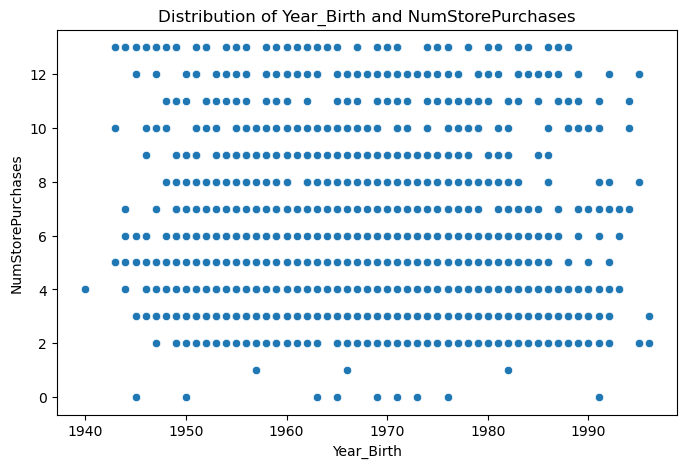

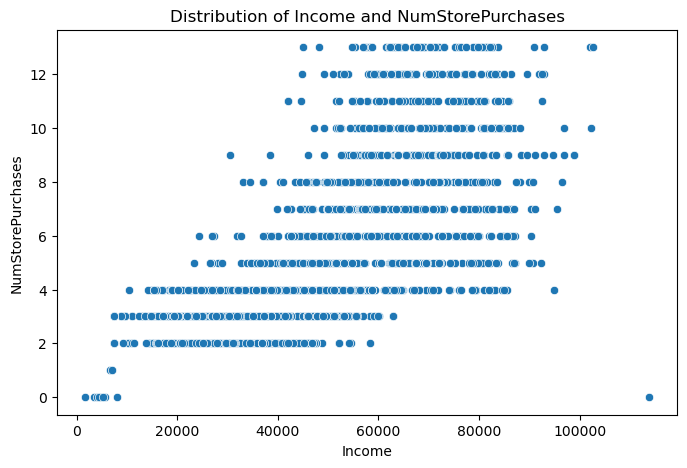

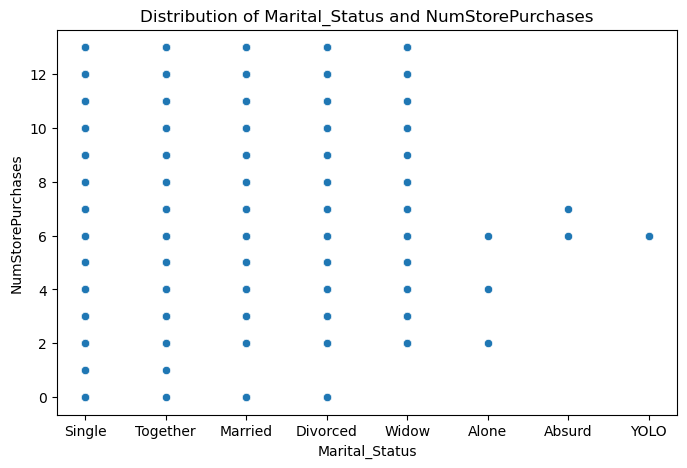

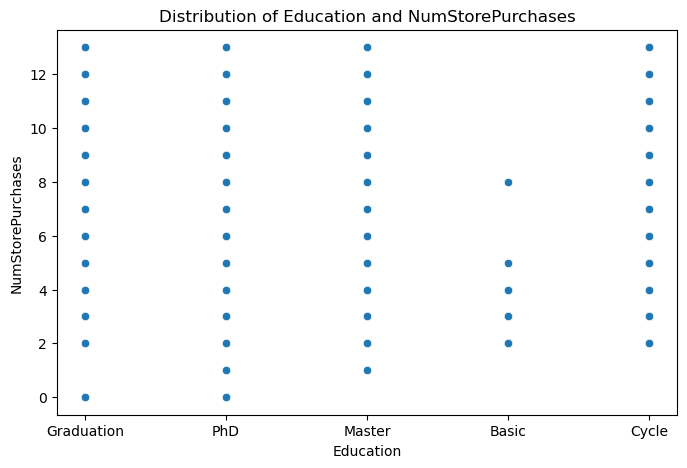

In [22]:
# Higher income tended to accept offer in the first campaign AcceptedCmp1 while Basic education tended NOT to accept 1st offer AcceptedCmp1.

# In the Placement plots, Birth year and marital status either single or married (except YOLO, alone, & absurd) did not contribute to NumStorePurchases. 
# However, high income status showed preference to NumStorePurchases. Basic education showed less purchase (NumStorePurchases)

# Plot distributions 
plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Year_Birth", y="NumStorePurchases")
plt.title('Distribution of Year_Birth and NumStorePurchases')
plt.xlabel('Year_Birth')
plt.ylabel('NumStorePurchases')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Income", y="NumStorePurchases")
plt.title('Distribution of Income and NumStorePurchases')
plt.xlabel('Income')
plt.ylabel('NumStorePurchases')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Marital_Status", y="NumStorePurchases")
plt.title('Distribution of Marital_Status and NumStorePurchases')
plt.xlabel('Marital_Status')
plt.ylabel('NumStorePurchases')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Education", y="NumStorePurchases")
plt.title('Distribution of Education and NumStorePurchases')
plt.xlabel('Education')
plt.ylabel('NumStorePurchases')
plt.show()

In [11]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.feature_selection import SelectKBest, f_classif, f_regression

# 1. DataFrame
X_raw, y_raw = make_classification(n_samples=2240, n_features=28, n_informative=6, random_state=42)
filtered_df = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(28)])
filtered_df['target'] = y_raw

# Separate features (X) and target (y)
X = filtered_df.drop(columns=['target'])
y = filtered_df['target']

# 2. Configure SelectKBest
# Use f_classif for classification or f_regression for regression tasks
k_features_to_select = 5
selector = SelectKBest(score_func=f_classif, k=k_features_to_select)

# 3. Fit and transform the data
X_new = selector.fit_transform(X, y)

# 4. Extract selected feature names and their statistical scores
selected_features = X.columns[selector.get_support()]
feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_
}).sort_values(by='Score', ascending=False)

# Output results
print("Selected Features:", list(selected_features))
print("\nFeature Scores Ranking:")
print(feature_scores.to_string(index=False))


Selected Features: ['feature_10', 'feature_12', 'feature_18', 'feature_22', 'feature_24']

Feature Scores Ranking:
   Feature       Score
feature_22 1352.684662
feature_12  336.073884
feature_10  229.182493
feature_18  207.762639
feature_24   81.757075
feature_25    5.758531
feature_27    3.185054
 feature_9    2.847719
feature_23    2.488794
 feature_2    2.115715
feature_21    2.011455
 feature_7    1.899942
 feature_5    1.440760
feature_16    1.389416
feature_20    1.272968
feature_14    0.829182
 feature_8    0.665299
 feature_6    0.621935
 feature_4    0.539008
feature_26    0.435166
feature_17    0.394324
feature_19    0.324128
feature_13    0.204462
 feature_1    0.153327
 feature_0    0.081751
 feature_3    0.045146
feature_15    0.004763
feature_11    0.002615


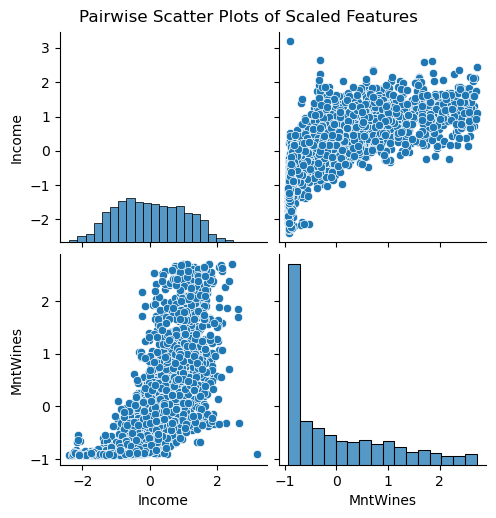

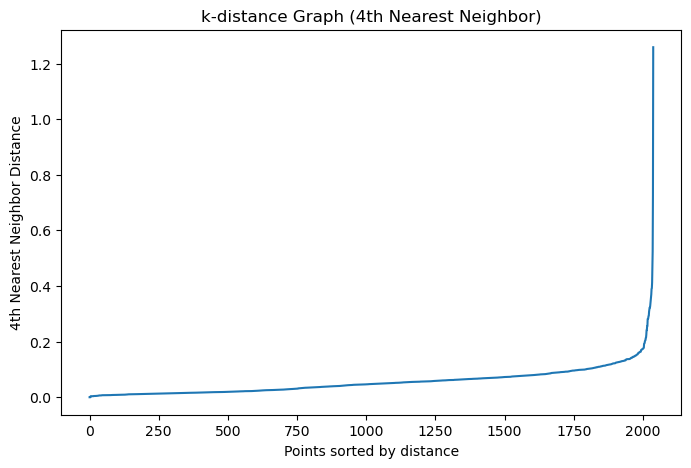

Clusters labels:
[-1  0]
Silhouette Score cannot be computed with less than 2 clusters


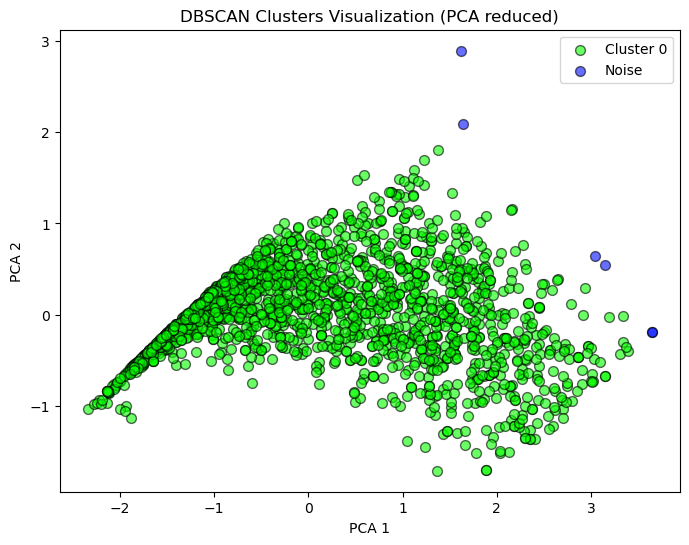

Number of clusters found: 1
Number of noise points: 6
                Income    MntWines
Cluster                           
-1       103018.333333  609.833333
 0        49552.202756  253.305118


In [8]:
# Data Preprocessing, Applied EDA & Feature Engineering
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Feature Selection & Preprocessing
# Selecting relevant numeric features for clustering - customize based on your dataset columns

features = filtered_df[['Income','MntWines']].copy()

# Handle missing values in features (if any)
features = features.dropna()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Pairwise scatter plot of scaled features
sns.pairplot(pd.DataFrame(X_scaled, columns=features.columns))
plt.suptitle('Pairwise Scatter Plots of Scaled Features', y=1.02)
plt.show()

# DBSCAN Clustering
# 1. Use k-distance graph to choose eps
neighbors = NearestNeighbors(n_neighbors=4)  # 4th nearest neighbor
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, 3], axis=0)

plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('k-distance Graph (4th Nearest Neighbor)')
plt.xlabel('Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.show()

# 2. Experiment with eps and min_samples (adjust eps based on graph)
eps_value = 0.3  # Example value, tune this
min_samples_value = 3

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
clusters = dbscan.fit_predict(X_scaled)

print(f'Clusters labels:\n{np.unique(clusters)}')

# 3. Silhouette score excluding noise (-1 label)
mask = clusters != -1
if len(set(clusters[mask])) > 1:
    sil_score = silhouette_score(X_scaled[mask], clusters[mask])
    print(f'Silhouette Score (excluding noise): {sil_score:.3f}')
else:
    print("Silhouette Score cannot be computed with less than 2 clusters")

# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
unique_labels = set(clusters)
colors = sns.color_palette('hsv', len(unique_labels))
for k, col in zip(unique_labels, colors):
    class_member_mask = (clusters == k)
    xy = X_pca[class_member_mask]
    label = 'Noise' if k == -1 else f'Cluster {k}'
    plt.scatter(xy[:, 0], xy[:, 1], c=[col], label=label, edgecolors='k', s=50, alpha=0.6)

plt.title('DBSCAN Clusters Visualization (PCA reduced)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.show()

# Cluster Analysis & Insights
df_clusters = df.loc[features.index].copy()  # align index with features
df_clusters['Cluster'] = clusters

# Number of clusters and noise points
num_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
num_noise = list(clusters).count(-1)

print(f'Number of clusters found: {num_clusters}')
print(f'Number of noise points: {num_noise}')

# Mean values of key features per cluster
cluster_summary = df_clusters.groupby('Cluster')[features.columns].mean()
print(cluster_summary)

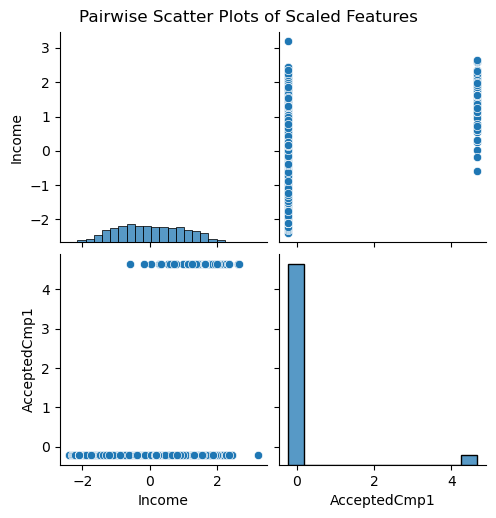

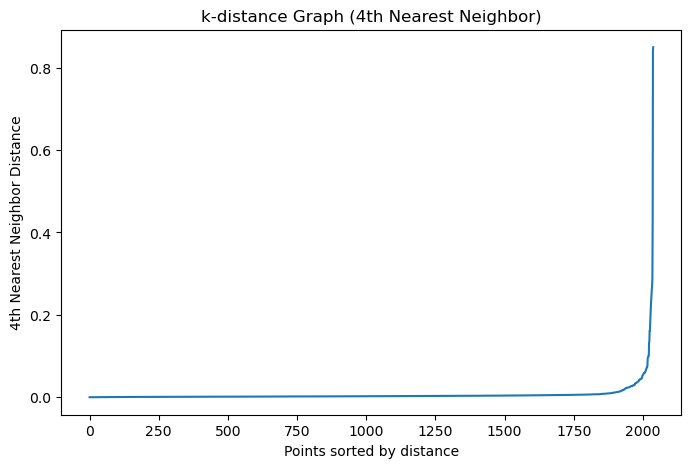

Clusters labels:
[-1  0  1]
Silhouette Score (excluding noise): 0.791


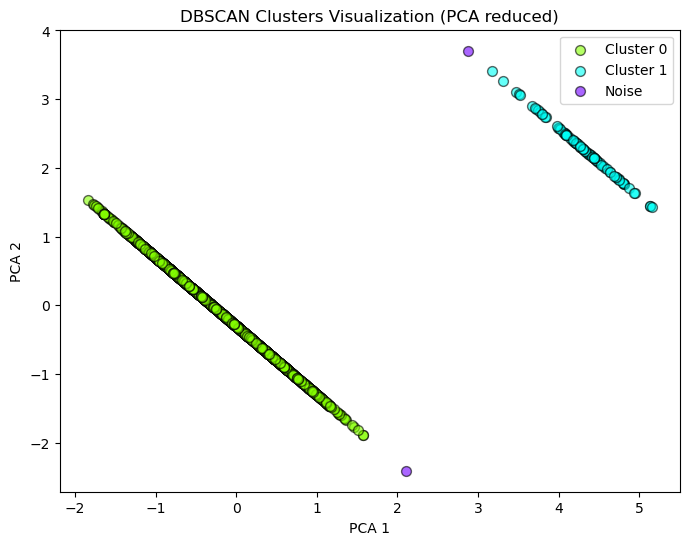

Number of clusters found: 2
Number of noise points: 2
               Income  AcceptedCmp1
Cluster                            
-1       75831.500000           0.5
 0       48377.139188           0.0
 1       78272.280899           1.0


In [28]:
# Feature Selection & Preprocessing
# Selecting relevant numeric features for clustering - customize based on your dataset columns

features = filtered_df[['Income','AcceptedCmp1']].copy()

# Handle missing values in features (if any)
features = features.dropna()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Pairwise scatter plot of scaled features
sns.pairplot(pd.DataFrame(X_scaled, columns=features.columns))
plt.suptitle('Pairwise Scatter Plots of Scaled Features', y=1.02)
plt.show()

# DBSCAN Clustering
# 1. Use k-distance graph to choose eps
neighbors = NearestNeighbors(n_neighbors=4)  # 4th nearest neighbor
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, 3], axis=0)

plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('k-distance Graph (4th Nearest Neighbor)')
plt.xlabel('Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.show()

# 2. Experiment with eps and min_samples (adjust eps based on graph)
eps_value = 0.3  # Example value, tune this
min_samples_value = 3

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
clusters = dbscan.fit_predict(X_scaled)

print(f'Clusters labels:\n{np.unique(clusters)}')

# 3. Silhouette score excluding noise (-1 label)
mask = clusters != -1
if len(set(clusters[mask])) > 1:
    sil_score = silhouette_score(X_scaled[mask], clusters[mask])
    print(f'Silhouette Score (excluding noise): {sil_score:.3f}')
else:
    print("Silhouette Score cannot be computed with less than 2 clusters")

# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
unique_labels = set(clusters)
colors = sns.color_palette('hsv', len(unique_labels))
for k, col in zip(unique_labels, colors):
    class_member_mask = (clusters == k)
    xy = X_pca[class_member_mask]
    label = 'Noise' if k == -1 else f'Cluster {k}'
    plt.scatter(xy[:, 0], xy[:, 1], c=[col], label=label, edgecolors='k', s=50, alpha=0.6)

plt.title('DBSCAN Clusters Visualization (PCA reduced)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.show()

# Cluster Analysis & Insights
df_clusters = df.loc[features.index].copy()  # align index with features
df_clusters['Cluster'] = clusters

# Number of clusters and noise points
num_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
num_noise = list(clusters).count(-1)

print(f'Number of clusters found: {num_clusters}')
print(f'Number of noise points: {num_noise}')

# Mean values of key features per cluster
cluster_summary = df_clusters.groupby('Cluster')[features.columns].mean()
print(cluster_summary)

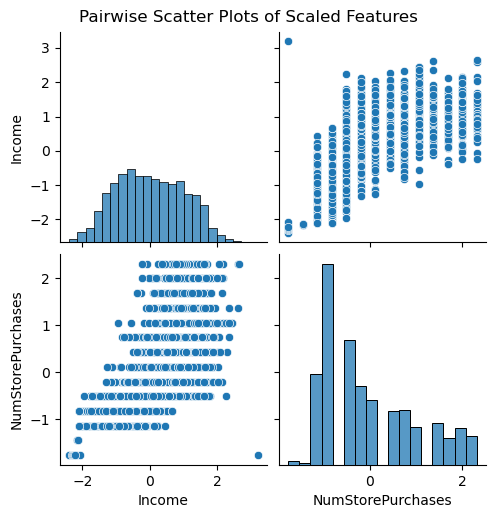

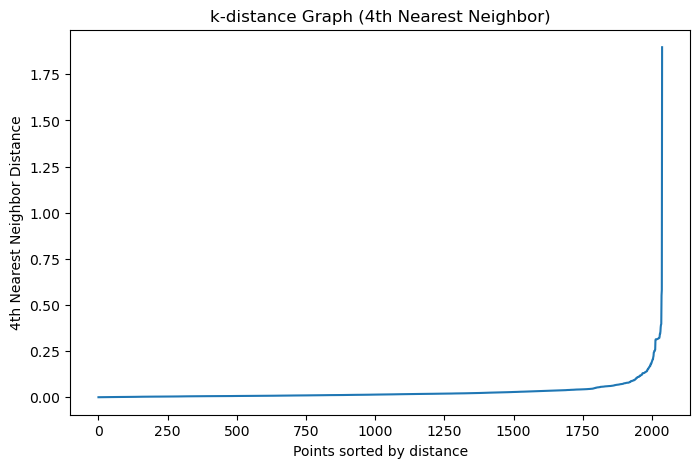

Clusters labels:
[-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Silhouette Score (excluding noise): 0.056


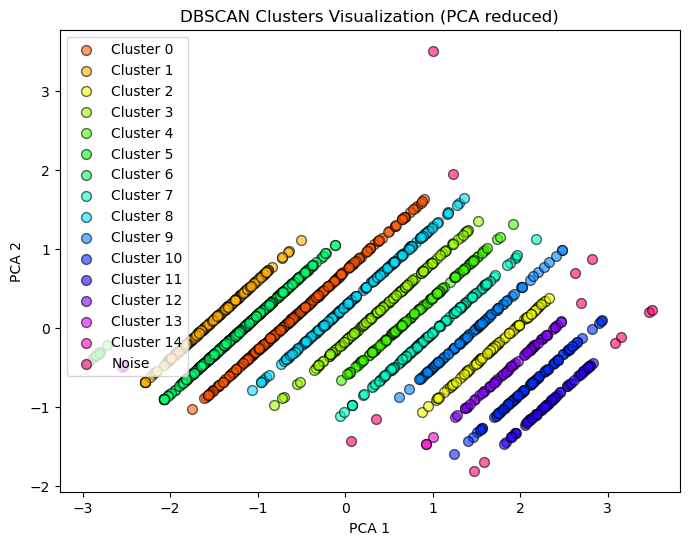

Number of clusters found: 15
Number of noise points: 13
               Income  NumStorePurchases
Cluster                                 
-1       80821.538462          10.076923
 0       43487.665552           4.000000
 1       30677.440367           2.000000
 2       69521.428571          10.000000
 3       59024.903846           6.000000
 4       63906.484615           7.000000
 5        4690.625000           0.000000
 6       32670.960663           3.000000
 7       62336.082707           8.000000
 8       56976.015789           5.000000
 9       68878.311111           9.000000
 10      69316.112360          12.000000
 11      69927.078125          13.000000
 12      70686.229508          11.000000
 13       6846.333333           1.000000
 14      42843.000000          11.000000


In [9]:
# Feature Selection & Preprocessing
# Selecting relevant numeric features for clustering - customize based on your dataset columns

features = filtered_df[['Income','NumStorePurchases']].copy()

# Handle missing values in features (if any)
features = features.dropna()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Pairwise scatter plot of scaled features
sns.pairplot(pd.DataFrame(X_scaled, columns=features.columns))
plt.suptitle('Pairwise Scatter Plots of Scaled Features', y=1.02)
plt.show()

# DBSCAN Clustering
# 1. Use k-distance graph to choose eps
neighbors = NearestNeighbors(n_neighbors=4)  # 4th nearest neighbor
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, 3], axis=0)

plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('k-distance Graph (4th Nearest Neighbor)')
plt.xlabel('Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.show()

# 2. Experiment with eps and min_samples (adjust eps based on graph)
eps_value = 0.3  # Example value, tune this
min_samples_value = 3

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
clusters = dbscan.fit_predict(X_scaled)

print(f'Clusters labels:\n{np.unique(clusters)}')

# 3. Silhouette score excluding noise (-1 label)
mask = clusters != -1
if len(set(clusters[mask])) > 1:
    sil_score = silhouette_score(X_scaled[mask], clusters[mask])
    print(f'Silhouette Score (excluding noise): {sil_score:.3f}')
else:
    print("Silhouette Score cannot be computed with less than 2 clusters")

# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
unique_labels = set(clusters)
colors = sns.color_palette('hsv', len(unique_labels))
for k, col in zip(unique_labels, colors):
    class_member_mask = (clusters == k)
    xy = X_pca[class_member_mask]
    label = 'Noise' if k == -1 else f'Cluster {k}'
    plt.scatter(xy[:, 0], xy[:, 1], c=[col], label=label, edgecolors='k', s=50, alpha=0.6)

plt.title('DBSCAN Clusters Visualization (PCA reduced)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.show()

# Cluster Analysis & Insights
df_clusters = df.loc[features.index].copy()  # align index with features
df_clusters['Cluster'] = clusters

# Number of clusters and noise points
num_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
num_noise = list(clusters).count(-1)

print(f'Number of clusters found: {num_clusters}')
print(f'Number of noise points: {num_noise}')

# Mean values of key features per cluster
cluster_summary = df_clusters.groupby('Cluster')[features.columns].mean()
print(cluster_summary)

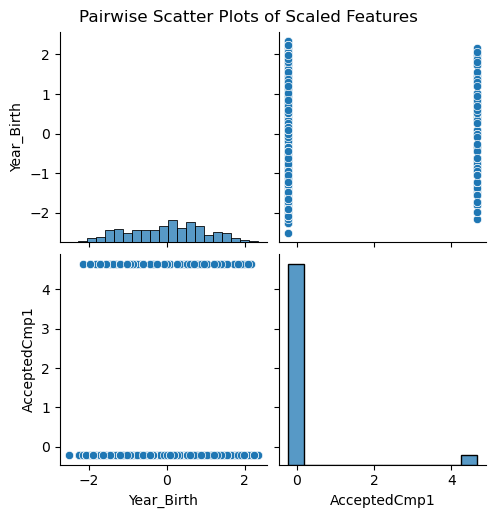

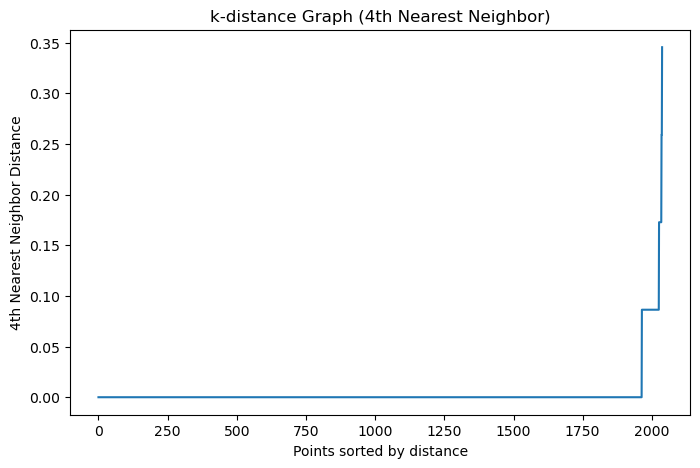

Clusters labels:
[0 1]
Silhouette Score (excluding noise): 0.776


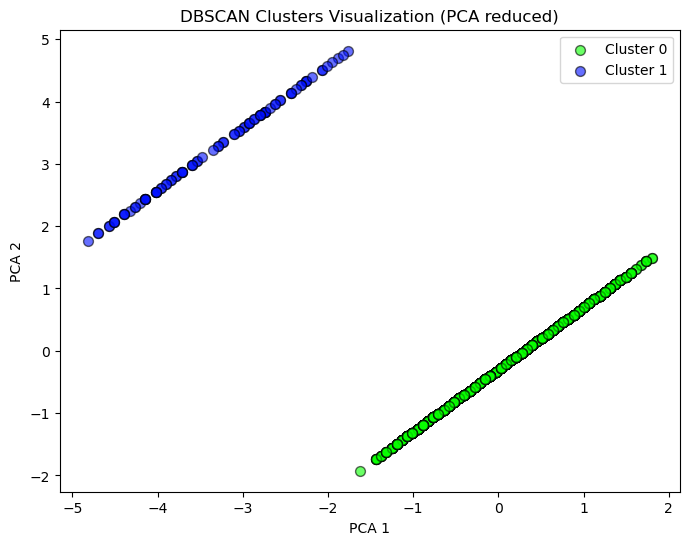

Number of clusters found: 2
Number of noise points: 0
          Year_Birth  AcceptedCmp1
Cluster                           
0        1969.045175           0.0
1        1968.466667           1.0


In [31]:
# Feature Selection & Preprocessing
# Selecting relevant numeric features for clustering - customize based on your dataset columns

features = filtered_df[['Year_Birth','AcceptedCmp1']].copy()

# Handle missing values in features (if any)
features = features.dropna()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Pairwise scatter plot of scaled features
sns.pairplot(pd.DataFrame(X_scaled, columns=features.columns))
plt.suptitle('Pairwise Scatter Plots of Scaled Features', y=1.02)
plt.show()

# DBSCAN Clustering
# 1. Use k-distance graph to choose eps
neighbors = NearestNeighbors(n_neighbors=4)  # 4th nearest neighbor
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, 3], axis=0)

plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('k-distance Graph (4th Nearest Neighbor)')
plt.xlabel('Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.show()

# 2. Experiment with eps and min_samples (adjust eps based on graph)
eps_value = 0.3  # Example value, tune this
min_samples_value = 3

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
clusters = dbscan.fit_predict(X_scaled)

print(f'Clusters labels:\n{np.unique(clusters)}')

# 3. Silhouette score excluding noise (-1 label)
mask = clusters != -1
if len(set(clusters[mask])) > 1:
    sil_score = silhouette_score(X_scaled[mask], clusters[mask])
    print(f'Silhouette Score (excluding noise): {sil_score:.3f}')
else:
    print("Silhouette Score cannot be computed with less than 2 clusters")

# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
unique_labels = set(clusters)
colors = sns.color_palette('hsv', len(unique_labels))
for k, col in zip(unique_labels, colors):
    class_member_mask = (clusters == k)
    xy = X_pca[class_member_mask]
    label = 'Noise' if k == -1 else f'Cluster {k}'
    plt.scatter(xy[:, 0], xy[:, 1], c=[col], label=label, edgecolors='k', s=50, alpha=0.6)

plt.title('DBSCAN Clusters Visualization (PCA reduced)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.show()

# Cluster Analysis & Insights
df_clusters = df.loc[features.index].copy()  # align index with features
df_clusters['Cluster'] = clusters

# Number of clusters and noise points
num_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
num_noise = list(clusters).count(-1)

print(f'Number of clusters found: {num_clusters}')
print(f'Number of noise points: {num_noise}')

# Mean values of key features per cluster
cluster_summary = df_clusters.groupby('Cluster')[features.columns].mean()
print(cluster_summary)

In [13]:
# NumCatalogPurchases (number of purchases made using a catalogue) and NumStorePurchases number of purchases made directly in stores) are positively correlated at 0.52

# import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# --- 1. SETUP ORIGINAL DATA ---
X_raw, y_raw = make_classification(n_samples=2240, n_features=28, n_informative=6, random_state=42)
df = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(28)])
df['NumStorePurchases'] = y_raw

# --- 2. CREATE THE FILTERED_DF ---
# (Example filter: keeping only rows where feature_0 is positive)
filtered_df = df[df['feature_0'] > 0].reset_index(drop=True)
print(f"Original shape: {df.shape} | Filtered shape: {filtered_df.shape}\n")

# --- 3. SEPARATE FEATURES AND TARGET ---
# Drop the target column to get features (X), keep only target for (y)
X = filtered_df.drop(columns=['NumStorePurchases'])
y = filtered_df['NumStorePurchases']

# --- 4. TRAIN-TEST SPLIT ---
# Splits data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 5. MODEL TRAINING ---
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# --- 6. EVALUATION ---
predictions = model.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, predictions):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, predictions))


Original shape: (2240, 29) | Filtered shape: (1138, 29)

Accuracy Score: 0.8596

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.81      0.85       116
           1       0.82      0.91      0.86       112

    accuracy                           0.86       228
   macro avg       0.86      0.86      0.86       228
weighted avg       0.86      0.86      0.86       228



In [14]:
# --- 1. SETUP ORIGINAL DATA ---
X_raw, y_raw = make_classification(n_samples=2240, n_features=28, n_informative=6, random_state=42)
df = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(28)])
df['AcceptedCmp1'] = y_raw

# --- 2. CREATE THE FILTERED_DF ---
# (Example filter: keeping only rows where feature_0 is positive)
filtered_df = df[df['feature_0'] > 0].reset_index(drop=True)
print(f"Original shape: {df.shape} | Filtered shape: {filtered_df.shape}\n")

# --- 3. SEPARATE FEATURES AND TARGET ---
# Drop the target column to get features (X), keep only target for (y)
X = filtered_df.drop(columns=['AcceptedCmp1'])
y = filtered_df['AcceptedCmp1']

# --- 4. TRAIN-TEST SPLIT ---
# Splits data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 5. MODEL TRAINING ---
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# --- 6. EVALUATION ---
predictions = model.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, predictions):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, predictions))


Original shape: (2240, 29) | Filtered shape: (1138, 29)



KeyError: "['Income'] not found in axis"